In [8]:
from req_functions_from_ApproxSP import *

In [9]:
## Two for One Code

import itertools
import copy

def generate_sw_manipulations(w_pref):
    """
    Sw: Move any two distinct men to top of w's list in any order.
    """
    manipulations = []
    for mi, mj in itertools.permutations(w_pref, 2): 
        rest = [m for m in w_pref if m != mi and m != mj]
        new_pref = [mi, mj] + rest
        manipulations.append(new_pref)
    return manipulations


def generate_sm_manipulations(m_pref, mu_m):
    """
    Sm: Promote µ(m) to top, then for every other woman, promote her to top of that list.
    """
    sm = []
    bm = [mu_m] + [w for w in m_pref if w != mu_m]
    sm.append(bm)

    for w0 in bm[1:]:  # exclude mu(m) which is already at the top
        manipulated = [w0] + [w for w in bm if w != w0]
        sm.append(manipulated)

    return sm


def two_for_one(mpref, wpref, accomplice, beneficiary, initial_matching):
    #initial_matching = gale_shapley(mpref, wpref)
    mpref_prime = copy.deepcopy(mpref)
    wpref_prime = copy.deepcopy(wpref)
    best_matching = initial_matching

    accomplice_pref = mpref[accomplice - 1] 
    beneficiary_pref = wpref[beneficiary - 1]

    Sw = generate_sw_manipulations(beneficiary_pref)

    for w_misreport in Sw:
        #t5 = time.perf_counter()

        Sm = generate_sm_manipulations(accomplice_pref, initial_matching[accomplice - 1])

        for m_misreport in Sm:
            #t6 = time.perf_counter()
            mpref_prime[accomplice - 1] = m_misreport 
            wpref_prime[beneficiary - 1] = w_misreport
            new_matching = gale_shapley(mpref_prime, wpref_prime)

            new_w_pairing = new_matching[beneficiary - 1]
            new_m_pairing = new_matching[accomplice - 1]

            if beneficiary_pref.index(new_w_pairing) < beneficiary_pref.index(best_matching[beneficiary - 1]) and best_matching[accomplice - 1] == new_m_pairing:
                best_matching = new_matching
                accomplice_pref = m_misreport
                beneficiary_pref = w_misreport
        #t7 = time.perf_counter()
        #print(f"Time for t5 - t6: {t6 - t5:.4f} seconds")
        #print(f"Time for t6 - t7: {t7 - t6:.4f} seconds")
    return best_matching, accomplice_pref, beneficiary_pref

**Mallows**

In [16]:
import pandas as pd
import ast 

df = pd.read_csv("mallows_gain_test2.csv")


In [ ]:
results = []

for idx, row in tqdm(df.iterrows()):
    mpref, wpref = ast.literal_eval(row["preferences"]) 
    mpref = [[int(x) for x in sublist] for sublist in mpref]
    wpref = [[int(x) for x in sublist] for sublist in wpref]

    n = len(mpref)
    #original_matching = df["original matchings"][idx]

    original_matching_raw = df["original matchings"][idx]
    original_matching_list = ast.literal_eval(original_matching_raw)
    original_matching = original_matching_list[0]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = abs(rk1 - rk2)  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

#print(results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('mallows_gain_test2.csv', index=False)


489it [09:43,  1.20s/it]

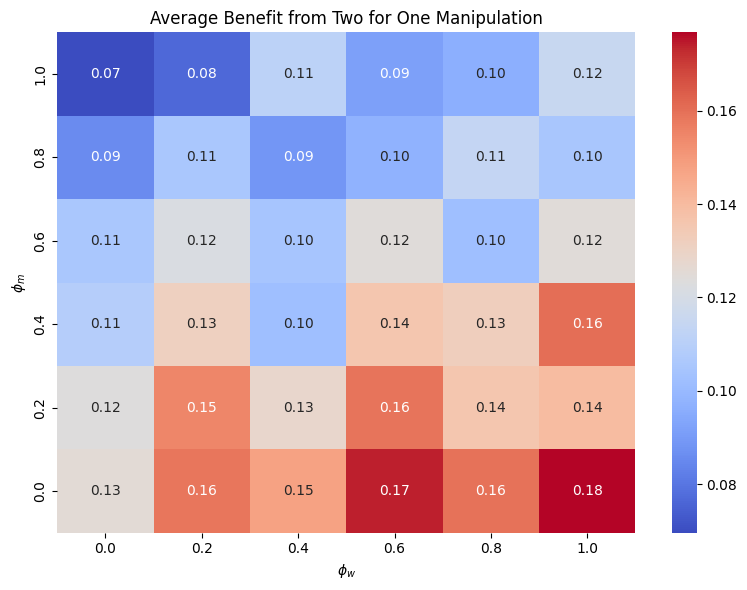

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


phi_m_list = []
phi_w_list = []
avg_benefit_list = []


for i, row in df.iterrows():
    accomplice_results = row["two_for_one_results"]


    benefits = [
        result[0]  # benefit value
        for manipulator_results in accomplice_results
        for result in manipulator_results
    ]

    avg_benefit = np.mean(benefits)

    phi_m_list.append(round(row["phi_m"], 2))
    phi_w_list.append(round(row["phi_w"], 2))
    avg_benefit_list.append(avg_benefit)


heatmap_df = pd.DataFrame({
    "phi_m": phi_m_list,
    "phi_w": phi_w_list,
    "avg_benefit": avg_benefit_list
})


heatmap_matrix = heatmap_df.pivot_table(index="phi_m", columns="phi_w", values="avg_benefit", aggfunc='mean')



plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Average Benefit from Two for One Manipulation")
plt.xlabel(r'$\phi_w$')
plt.ylabel(r"$\phi_m$")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


In [ ]:
results = []

for idx, row in df.iterrows():
    mpref, wpref = row["preferences"]
    n = len(mpref)
    original_matching = df["original_matchings"][idx]

    instance_results = []  # store all manipulator-accomplice outcomes for this row

    for manipulator in range(1, n+1):
        manipulator_results = []  # all accomplices for this manipulator

        for accomplice in range(1, n+1):
            func_return = two_for_one(mpref, wpref, accomplice, manipulator, original_matching)
            new_matching = func_return[0]
            accomplice_pref_after, beneficiary_pref_after = func_return[1:]

            # --- compute benefit ---
            rk1 = rk2 = 1000
            for i in range(n):
                if original_matching[i] == manipulator:
                    partner1 = i + 1
                if new_matching[i] == manipulator:
                    partner2 = i + 1
            
            w_pref = wpref[manipulator - 1]
            for i in range(n):
                if w_pref[i] == partner1:
                    rk1 = i
                if w_pref[i] == partner2:
                    rk2 = i

            benefit = rk1 - rk2  # improvement (positive = better)

            # store for this accomplice
            manipulator_results.append([
                benefit,
                new_matching,
                accomplice_pref_after,
                beneficiary_pref_after
            ])

        # store for this manipulator
        instance_results.append(manipulator_results)

    # store results for this row
    results.append(instance_results)

# attach to df
df["two_for_one_results"] = results
df.to_csv('mallows_gain.csv', index=False)
